<a href="https://colab.research.google.com/github/hamidharis/Zero2Hero/blob/03-mlp/Third.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import random
import torch.nn.functional as F

In [ ]:
names = open('names.txt').read().splitlines()
characters = ['.']+sorted(set(''.join(names)))
stoi = {s:i for i,s in enumerate(characters)}
itos = {i:s for s,i in stoi.items()}

In [ ]:
block_size = 3
x,y = [],[]
for name in names:
    context = [0]*block_size
    for ch in name+'.':
      idx = stoi[ch]
      x.append(context)
      y.append(idx)
      context = context[1:]  + [idx]

x = torch.tensor(x)
y = torch.tensor(y)

In [ ]:
y.shape

torch.Size([228146])

In [ ]:
x.shape

torch.Size([228146, 3])

In [ ]:
def build_dataset(names):
  block_size = 3
  x,y = [],[]
  for name in names:
    context = [0]*block_size
    for ch in name+'.':
      idx = stoi[ch]
      x.append(context)
      y.append(idx)
      context = context[1:]  + [idx]

  x = torch.tensor(x)
  y = torch.tensor(y)

  return x,y

In [ ]:
random.seed(32)
random.shuffle(names)
split_a = int(0.8*(len(names)))
split_b = int(0.9*(len(names)))

x_train,y_train = build_dataset(names[:split_a])
x_val,y_val = build_dataset(names[split_a:split_b])
x_test,y_test = build_dataset(names[split_b:])

In [ ]:
torch.manual_seed(32)
C = torch.randn(27,2) #Random Wieght Matrix(Embedding) 27 for 27 chars and 2 is some dimension

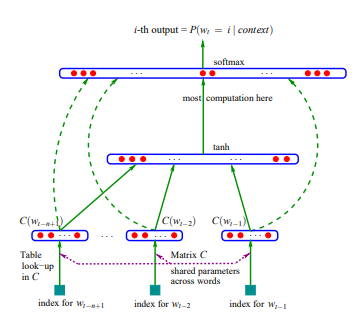

Layer 01 : Now what we want is to use this lookup table C for every character example of x

In [ ]:
torch.manual_seed(32)
emb = C[x]
W1 = torch.randn(6,100)
b1 = torch.randn(100)
h = emb.view(-1,6) @ W1 + b1

Layer 02 : Applying tanh()

In [ ]:
torch.manual_seed(32)
W2 = torch.randn(100,27)
b2 = torch.randn(27)
logits = torch.tanh(h) @ W2 + b2

Layer 03 : Applying Softmax()

In [ ]:
parameters = [C,W1,b1,W2,b2]
no_of_params = 0
for p in parameters:
  p.requires_grad = True
  no_of_params+=p.nelement()

In [ ]:
torch.tensor(32)

tensor(32)

In [ ]:
torch.manual_seed(32)
counts = logits.exp()
probs = counts/counts.sum(1,keepdim=True) #Rows of this matrix are the probability distributions across 27 classes(alphabets as next characters)
loss = -probs[torch.arange(228146),y].log().mean()
loss

tensor(12.5308)

Now we'll try and reduce the loss as much as possible by training the whole neural net

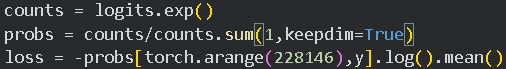

These 3 lines can be replaced by a single Cross Entropy Loss

In [ ]:
C = torch.randn(27,10)
W1 = torch.randn(30,300)
b1 = torch.randn(300)
W2 = torch.randn(300,27)
b2 = torch.randn(27)
parameters = [C,W1,b1,W2,b2]
no_of_params = 0
for p in parameters:
  p.requires_grad = True
  no_of_params+=p.nelement()
print(no_of_params)

17697


In [ ]:
lri = []
lossi = []
torch.manual_seed(32)
#Forward Pass
for _ in range(5000):
  emb = C[x]

  logits = torch.tanh(emb.view(-1,30)@W1+b1)
  logits = logits@W2+b2
  #Calculate the loss
  loss = F.cross_entropy(logits,y)
  #Zero Grad
  for p in parameters:
    p.grad = None
  #Loss Backwards
  loss.backward()
  for p in parameters:
    p.data+=-0.1*p.grad

  lossi.append(loss.item())


print(f'Loss : {loss.item()}')

KeyboardInterrupt: 